## Objective : 
Analyze retail sales data to identify top-performing products, regional trends, and key business KPIs (Revenue, Profit, Growth rate, customer segmentation)

## Dataset : 
Sample Superstore dataset - [9994] rows, [21] columns

In [1]:
import pandas as pd


In [2]:
df = pd.read_csv('../data/Sample _ Superstore.csv')

## 1. Data Exploration
Checking structure ,data types and summary statistics before cleaning

In [3]:
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
df.shape


(9994, 21)

In [5]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [7]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [8]:
# per-column missing counts
df.isnull().sum()


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

**Finding:** 
No missing values found across all columns

In [9]:
# Data cleaning 
# checks duplicate rows
df.duplicated().sum()

np.int64(0)

**Finding:**
No duplicate rows found,no action needed

## 2. Data Cleaning:
Converting Order Date and Ship Date from string to datetime for time-based analysis.

In [10]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])   

## 3. Overall Business KPIs:

In [11]:
total_sales = round(df["Sales"].sum(), 2)
total_profit = round(df["Profit"].sum(), 2)
total_orders = df["Order ID"].nunique()
avg_order_value = round(total_sales / total_orders, 2)
profit_margin = round((total_profit / total_sales) * 100, 2)

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Average Order Value: ${avg_order_value:,.2f}")
print(f"Overall Profit Margin: {profit_margin}%")


Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5009
Average Order Value: $458.61
Overall Profit Margin: 12.47%


In [12]:
avg_sales = round(df["Sales"].mean(), 2)
avg_profit = round(df["Profit"].mean(), 2)

print(f"Average Sales per transaction: ${avg_sales:,.2f}")
print(f"Average Profit per transaction: ${avg_profit:,.2f}")

Average Sales per transaction: $229.86
Average Profit per transaction: $28.66


**Summary:**
Total Revenue: $2,297,200.86 | Total Profit: $286,397.02 | Total Orders: 5,009 | Average Order Value: $458.61 | Overall Profit Margin: 12.47%


##  Visualizations


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## 4. Category-Level Analysis
Comparing sales, profit, and discount behaviour across product categories.


In [14]:
df.groupby("Category")["Sales"].sum().round(2).sort_values(ascending=False)


Category
Technology         836154.03
Furniture          741999.80
Office Supplies    719047.03
Name: Sales, dtype: float64

In [15]:
df.groupby("Category")["Profit"].sum().round(2).sort_values(ascending=False)

Category
Technology         145454.95
Office Supplies    122490.80
Furniture           18451.27
Name: Profit, dtype: float64

In [16]:
category_margin = (df.groupby("Category")["Profit"].sum() / df.groupby("Category")["Sales"].sum() * 100).round(2)
category_margin.sort_values(ascending=False)

Category
Technology         17.40
Office Supplies    17.04
Furniture           2.49
dtype: float64

**Insight:** Technology (17.40%) and Office Supplies (17.04%) have healthy, comparable
profit margins, but Furniture lags at just 2.49% — nearly 7x lower despite
contributing meaningfully to overall sales. This suggests Furniture's revenue isn't
converting into profit efficiently.

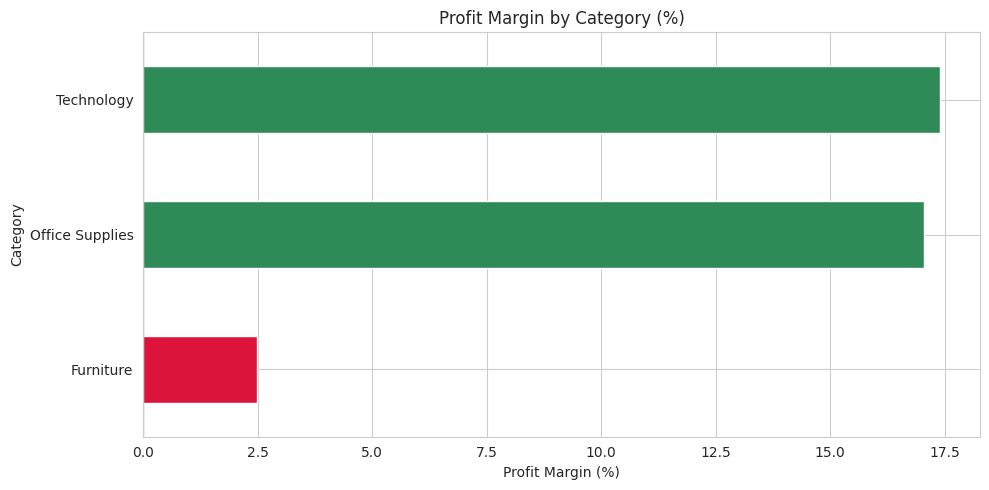

In [17]:
cat_margin = (df.groupby("Category")["Profit"].sum() / df.groupby("Category")["Sales"].sum() * 100).round(2).sort_values()

colors = ["crimson" if v < 5 else "seagreen" for v in cat_margin]
cat_margin.plot(kind="barh", color=colors)
plt.title("Profit Margin by Category (%)")
plt.xlabel("Profit Margin (%)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Chart Insight:** You can literally see it here - Furniture's bar barely gets off the ground compared to Technology and Office Supplies. Makes the 7x margin gap a lot easier to process than the raw percentages.

In [18]:
sub_category_margin = (df.groupby("Sub-Category")["Profit"].sum() / df.groupby("Sub-Category")["Sales"].sum() * 100).round(2)
sub_category_margin.sort_values(ascending=False)

Sub-Category
Labels         44.42
Paper          43.39
Envelopes      42.27
Copiers        37.20
Fasteners      31.40
Accessories    25.05
Art            24.07
Appliances     16.87
Binders        14.86
Furnishings    14.24
Phones         13.49
Storage         9.51
Chairs          8.10
Machines        1.79
Supplies       -2.55
Bookcases      -3.02
Tables         -8.56
dtype: float64

**Insight:** Three sub-categories are actively losing money: Tables (-8.56%),
Bookcases (-3.02%), and Supplies (-2.55%). Tables and Bookcases explain Furniture's
poor category-level margin, but Supplies is a hidden problem — Office Supplies looks
healthy overall (17.04%) only because strong performers like Labels (44.42%) and
Paper (43.39%) mask the loss happening in Supplies. Category-level averages alone
would have missed this; sub-category analysis was necessary to find it

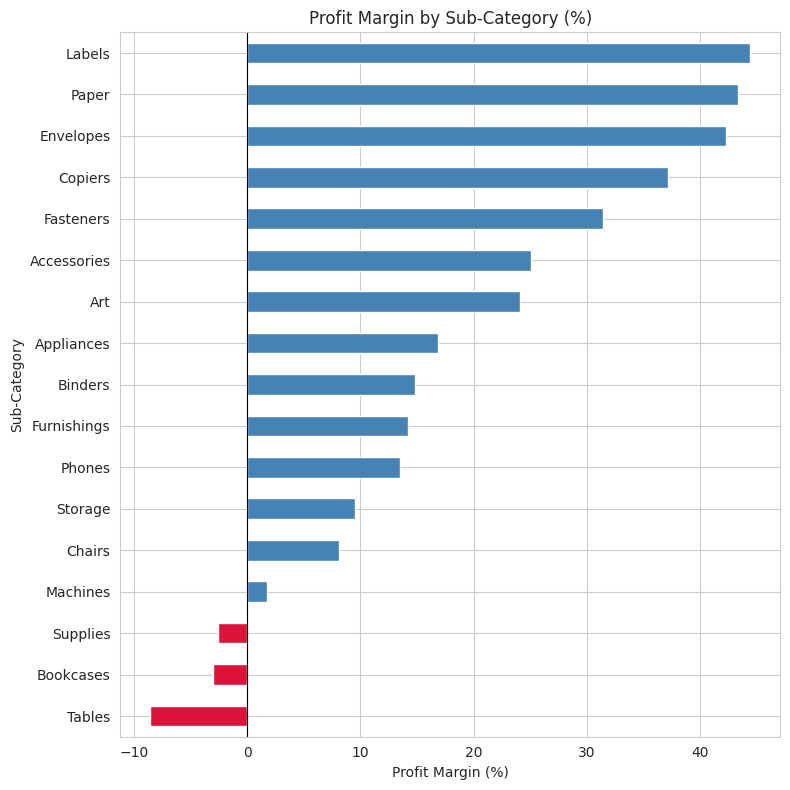

In [19]:
sub_margin = (df.groupby("Sub-Category")["Profit"].sum() / df.groupby("Sub-Category")["Sales"].sum() * 100).round(2).sort_values()

colors = ["crimson" if v < 0 else "steelblue" for v in sub_margin]
sub_margin.plot(kind="barh", color=colors, figsize=(8,8))
plt.title("Profit Margin by Sub-Category (%)")
plt.xlabel("Profit Margin (%)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Chart Insight:** Only three bars dip below zero - Tables, Bookcases and Supplies - and Tables is clearly the worst offender by a good margin. Everything above Chairs is at least a healthy double-digit margin, so the problem really is isolated to a handful of sub-categories, not the whole business.

**Recommendation:** Review discount policy specifically for Tables, Bookcases, and
Supplies — either reduce discount depth on these items or reassess their pricing,
since they are eroding profit gained elsewhere in the business.

In [20]:
(df.groupby("Category")["Discount"].mean()*100).round(2).sort_values(ascending=False)  

Category
Furniture          17.39
Office Supplies    15.73
Technology         13.23
Name: Discount, dtype: float64

**Insight:** Furniture carries the highest average discount (17.39%) among all categories
and the lowest profit margin (2.49%) — nearly 7x lower than Technology and Office Supplies,
which both maintain healthy ~17% margins despite Technology having the lowest discount
(13.23%). 

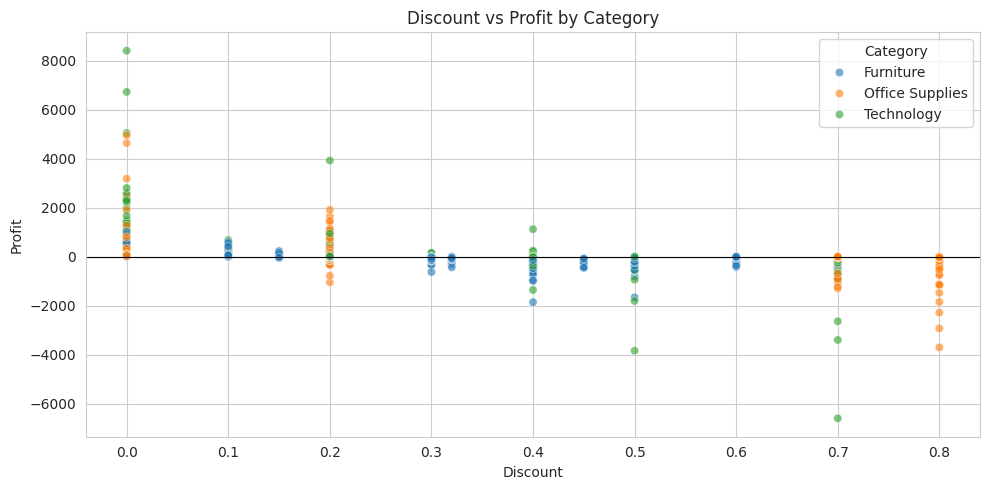

In [21]:
sns.scatterplot(data=df, x="Discount", y="Profit", hue="Category", alpha=0.6)
plt.title("Discount vs Profit by Category")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**Chart Insight:** Once discount goes past roughly 20-30%, profit points start dropping below the zero line for basically every category, and by 70-80% discount almost everything is a loss. Furniture (blue) and Technology (green) have some of the biggest losses at high discount levels, which lines up with the margin numbers above - discounting that deep is basically handing away all the profit.

## 5. Regional Analysis
Comparing sales and profit performance across regions and states.

In [22]:
df.groupby("Region")["Sales"].sum().round(2).sort_values(ascending=False)


Region
West       725457.82
East       678781.24
Central    501239.89
South      391721.90
Name: Sales, dtype: float64

In [23]:
df.groupby("Region")["Profit"].sum().round(2).sort_values(ascending=False)



Region
West       108418.45
East        91522.78
South       46749.43
Central     39706.36
Name: Profit, dtype: float64

In [24]:
df.groupby("State")["Sales"].sum().round(2).sort_values(ascending=False)


State
California              457687.63
New York                310876.27
Texas                   170188.05
Washington              138641.27
Pennsylvania            116511.91
Florida                  89473.71
Illinois                 80166.10
Ohio                     78258.14
Michigan                 76269.61
Virginia                 70636.72
North Carolina           55603.16
Indiana                  53555.36
Georgia                  49095.84
Kentucky                 36591.75
New Jersey               35764.31
Arizona                  35282.00
Wisconsin                32114.61
Colorado                 32108.12
Tennessee                30661.87
Minnesota                29863.15
Massachusetts            28634.43
Delaware                 27451.07
Maryland                 23705.52
Rhode Island             22627.96
Missouri                 22205.15
Oklahoma                 19683.39
Alabama                  19510.64
Oregon                   17431.15
Nevada                   16729.10
Connecti

In [25]:
df.groupby("State")["Profit"].sum().round(2).sort_values(ascending=False)

State
California              76381.39
New York                74038.55
Washington              33402.65
Michigan                24463.19
Virginia                18597.95
Indiana                 18382.94
Georgia                 16250.04
Kentucky                11199.70
Minnesota               10823.19
Delaware                 9977.37
New Jersey               9772.91
Wisconsin                8401.80
Rhode Island             7285.63
Maryland                 7031.18
Massachusetts            6785.50
Missouri                 6436.21
Alabama                  5786.83
Oklahoma                 4853.96
Arkansas                 4008.69
Connecticut              3511.49
Nevada                   3316.77
Mississippi              3172.98
Utah                     2546.53
Vermont                  2244.98
Louisiana                2196.10
Nebraska                 2037.09
Montana                  1833.33
South Carolina           1769.06
New Hampshire            1706.50
Iowa                     1183.81
New 

**Insight:** California is the single highest-revenue state, and the West region leads on both sales and profit overall. However, sales and profit don't always move together at the state level — several states generate solid sales but comparatively thin profit, pointing to pricing or cost-efficiency issues specific to those markets rather than a demand problem.


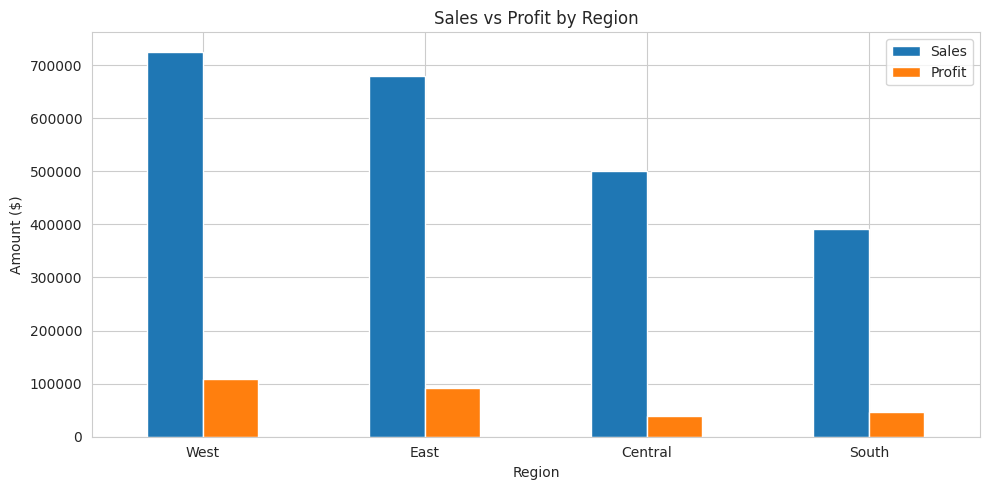

In [26]:
region_summary = df.groupby("Region")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
region_summary.plot(kind="bar")
plt.title("Sales vs Profit by Region")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Chart Insight:** West and East are ahead on both sales and profit, no surprise there. But look closely at Central vs South - Central actually has higher sales than South, yet South pulls in more profit. So Central isn't just behind, it's behind on efficiency too, not just size.

**Follow-up:** Chairs is a mid-pack sub-category by margin (positive but modest). Pulling one specific high-ticket chair product checks whether the discount-erodes-profit pattern found above holds at the individual order level, not just in aggregate.


In [27]:
df[df["Product Name"] == "HON 5400 Series Task Chairs for Big and Tall"][["Sales", "Discount", "Profit", "Quantity"]]

,Sales,Discount,Profit,Quantity
551,1121.568,0.2,0.000,2
1438,2453.430,0.3,-350.490,5
3077,981.372,0.3,-140.196,2
5170,3504.900,0.0,700.980,5
7243,4416.174,0.3,-630.882,9
8236,2803.920,0.2,0.000,5
9412,2803.920,0.2,0.000,5
9425,3785.292,0.1,420.588,6


**Insight:** The pattern holds at the individual order level. The same chair is profitable at 0% and 10% discount (+$700.98 and +$420.59), breaks even at 20% (two orders at exactly $0 profit), and loses money at 30% (-$140 to -$631 across three orders). A single product can swing from a solidly profitable item to a loss-maker purely based on the discount applied to it.


## 6. Top Customers and Products
Identifying the highest-value customers and best-selling products by sales.

In [28]:
# Customer analysis
df.groupby("Customer Name")["Sales"].sum().round(2).sort_values(ascending=False).head(10)

Customer Name
Sean Miller           25043.05
Tamara Chand          19052.22
Raymond Buch          15117.34
Tom Ashbrook          14595.62
Adrian Barton         14473.57
Ken Lonsdale          14175.23
Sanjit Chand          14142.33
Hunter Lopez          12873.30
Sanjit Engle          12209.44
Christopher Conant    12129.07
Name: Sales, dtype: float64

In [29]:
#Product analysis
df.groupby("Product Name")["Sales"].sum().round(2).sort_values(ascending=False).head(10)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.82
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.38
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.48
HON 5400 Series Task Chairs for Big and Tall                                   21870.58
GBC DocuBind TL300 Electric Binding System                                     19823.48
GBC Ibimaster 500 Manual ProClick Binding System                               19024.50
Hewlett Packard LaserJet 3310 Copier                                           18839.69
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.90
GBC DocuBind P400 Electric Binding System                                      17965.07
High Speed Automatic Electric Letter Opener                                    17030.31
Name: Sales, dtype: float64

In [30]:
top_10_products = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10).index

df[df["Product Name"].isin(top_10_products)].groupby("Product Name").agg(
    Category=("Category", "first"),
    Sub_Category=("Sub-Category", "first"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).round(2).sort_values("Total_Sales", ascending=False)

,Category,Sub_Category,Total_Sales,Total_Profit
Product Name,,,,
Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,61599.82,25199.93
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,Office Supplies,Binders,27453.38,7753.04
Cisco TelePresence System EX90 Videoconferencing Unit,Technology,Machines,22638.48,-1811.08
HON 5400 Series Task Chairs for Big and Tall,Furniture,Chairs,21870.58,0.00
GBC DocuBind TL300 Electric Binding System,Office Supplies,Binders,19823.48,2233.51
GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,Binders,19024.50,760.98
Hewlett Packard LaserJet 3310 Copier,Technology,Copiers,18839.69,6983.88
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",Technology,Machines,18374.90,4094.98
GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.07,-1878.17


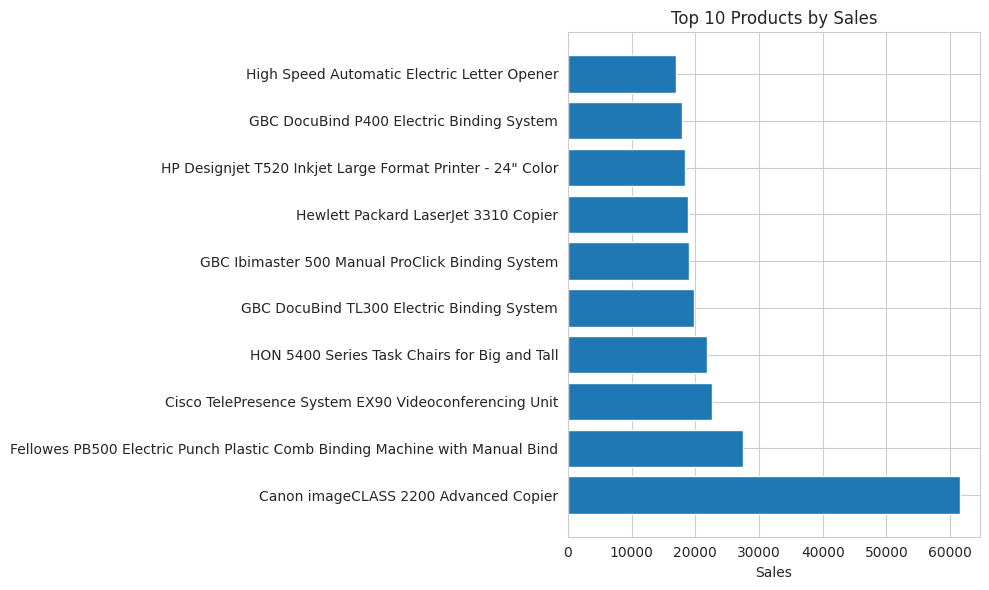

In [31]:
top_products = (
    df.groupby("Product Name")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10,6))
plt.barh(top_products.index, top_products.values)
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.tight_layout()
plt.show()

**Chart Insight:** Canon imageCLASS copier is way out in front of everything else, almost double the next closest product. After the top 2-3 products it flattens out quite a bit, so the top sellers list isn't as top-heavy as it might look from the table alone.

**Follow-up:** Since discount depth showed up as a major profit driver above, it's worth checking whether that relationship holds within a single sub-category — grouping Chairs orders by discount band isolates the effect from category-level noise.


In [32]:
df[df["Sub-Category"] == "Chairs"].groupby("Discount")["Profit"].agg(["mean", "count"]).round(2)

,mean,count
Discount,,
0.0,164.91,133
0.1,93.57,76
0.2,17.13,250
0.3,-42.64,158


**Insight:** Within Chairs alone, mean profit per order falls in a straight line as discount increases — $164.91 at 0% discount, $93.57 at 10%, $17.13 at 20%, and a loss of -$42.64 at 30% (based on 158 orders at that level, so this isn't a fluke). This is the clearest single piece of evidence that discounting past a certain point isn't just correlated with lower margins — it's actively causing the sub-category-level losses seen earlier.


**Insights:**
A small number of customers contribute a significant share of total revenue.


## 7. Customer Segment Analysis
Comparing sales and profit across customer segments (Consumer, Corporate, Home Office).


In [33]:
df.groupby("Segment")["Sales"].sum().round(2).sort_values(ascending=False)



Segment
Consumer       1161401.34
Corporate       706146.37
Home Office     429653.15
Name: Sales, dtype: float64

In [34]:
df.groupby("Segment")["Profit"].sum().round(2).sort_values(ascending=False)

Segment
Consumer       134119.21
Corporate       91979.13
Home Office     60298.68
Name: Profit, dtype: float64

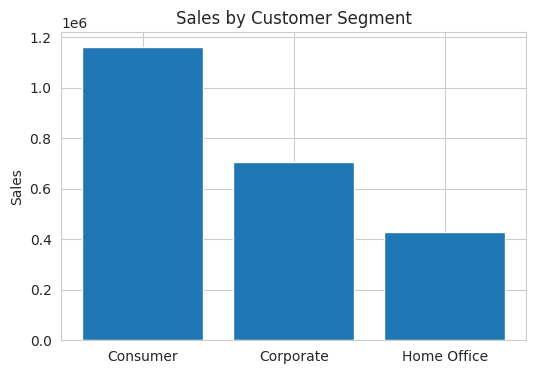

In [35]:
segment_sales = df.groupby("Segment")["Sales"].sum()

plt.figure(figsize=(6,4))
plt.bar(segment_sales.index, segment_sales.values)
plt.title("Sales by Customer Segment")
plt.ylabel("Sales")
plt.show()

**Chart Insight:** Consumer segment towers over the other two - it's not even close. So most of the revenue is coming from individual buyers rather than businesses, which is worth keeping in mind for any retention or marketing push.

**Insights:**
Consumers lead both sales and profit

## 8. Shipping Method Analysis
Comparing sales volume across shipping modes.

In [36]:

df.groupby("Ship Mode")["Sales"].sum().round(2).sort_values(ascending=False) 

Ship Mode
Standard Class    1358215.74
Second Class       459193.57
First Class        351428.42
Same Day           128363.12
Name: Sales, dtype: float64

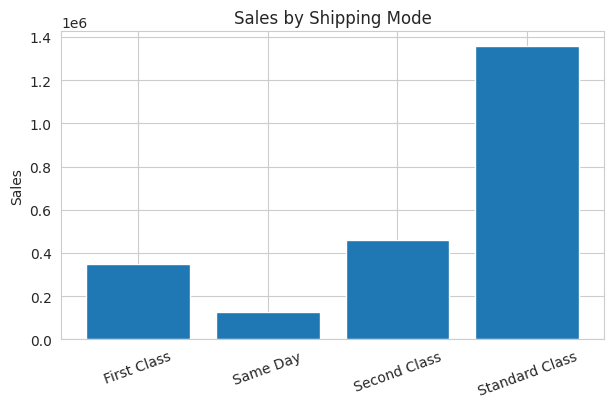

In [37]:
ship_sales = df.groupby("Ship Mode")["Sales"].sum()

plt.figure(figsize=(7,4))
plt.bar(ship_sales.index, ship_sales.values)
plt.title("Sales by Shipping Mode")
plt.ylabel("Sales")
plt.xticks(rotation=20)
plt.show()

**Chart Insight:** Standard Class completely dwarfs the other shipping options. Most customers clearly aren't in a rush, which is useful to know if fulfillment costs ever need optimizing.

**Insights:**
 Standard Class dominates ($1.36M vs. next-highest $459K for Second Class) — most orders aren't urgent.


In [38]:
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

shipping_delay = (
    df.groupby("Ship Mode")["Shipping Days"]
      .mean()
      .sort_values()
)

shipping_delay

Ship Mode
Same Day          0.044199
First Class       2.182705
Second Class      3.238046
Standard Class    5.006535
Name: Shipping Days, dtype: float64

## 9. Time-Based Trend Analysis

In [39]:
df["Month"] = df["Order Date"].dt.month_name()
df["Year"] = df["Order Date"].dt.year

In [40]:
df["Month Number"] = df["Order Date"].dt.month
monthly_sales = df.groupby(["Year", "Month Number", "Month"])["Sales"].sum().round(2).reset_index()


In [41]:
monthly_sales = monthly_sales.sort_values(["Year", "Month Number"]).reset_index(drop=True)
monthly_sales["Growth Rate (%)"] = (
    monthly_sales["Sales"]
        .pct_change()
        .mul(100)
        .round(2)
)

monthly_sales

,Year,Month Number,Month,Sales,Growth Rate (%)
0,2014,1,January,14236.90,NaN
1,2014,2,February,4519.89,-68.25
2,2014,3,March,55691.01,1132.13
3,2014,4,April,28295.34,-49.19
4,2014,5,May,23648.29,-16.42
5,2014,6,June,34595.13,46.29
6,2014,7,July,33946.39,-1.88
7,2014,8,August,27909.47,-17.78
8,2014,9,September,81777.35,193.01
9,2014,10,October,31453.39,-61.54


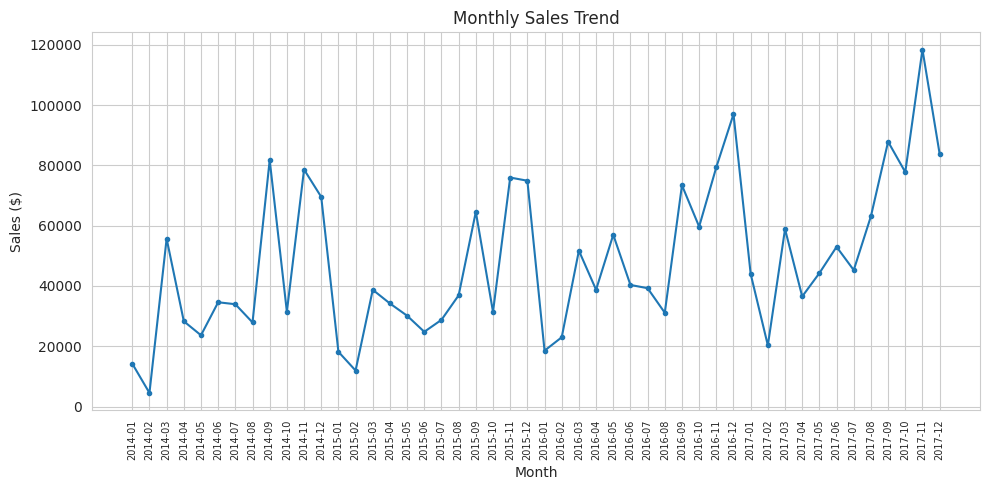

In [42]:
monthly_sales["Period"] = monthly_sales["Year"].astype(str) + "-" + monthly_sales["Month Number"].astype(str).str.zfill(2)

plt.plot(monthly_sales["Period"], monthly_sales["Sales"], marker="o", markersize=3)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

**Insight:** Sales clearly trend upward from 2014 to 2017 overall, but it's not a smooth climb - there's a repeating pattern of a big spike around Nov-Dec each year followed by a January-February dip. Looks like a seasonal, holiday-driven pattern rather than steady growth, which matters for inventory planning.

## 10. Negative Profit Products

In [43]:
negative_products = (
    df.groupby("Product Name")["Profit"]
      .sum()
      .reset_index()
)
negative_products = negative_products[
    negative_products["Profit"] < 0
].sort_values("Profit")

negative_products.head(15)

,Product Name,Profit
475,Cubify CubeX 3D Printer Double Head Print,-8879.9704
985,Lexmark MX611dhe Monochrome Laser Printer,-4589.9730
476,Cubify CubeX 3D Printer Triple Head Print,-3839.9904
425,Chromcraft Bull-Nose Wood Oval Conference Tabl...,-2876.1156
376,Bush Advantage Collection Racetrack Conference...,-1934.3976
683,GBC DocuBind P400 Electric Binding System,-1878.1662
444,Cisco TelePresence System EX90 Videoconferenci...,-1811.0784
1043,Martin Yale Chadless Opener Electric Letter Op...,-1299.1836
285,Balt Solid Wood Round Tables,-1201.0581
364,BoxOffice By Design Rectangular and Half-Moon ...,-1148.4375


# Final Business Recommendations

1. Reduce excessive discounts on Furniture, especially Tables and Bookcases, to improve profitability.

2. Investigate loss-making sub-categories — Tables (-8.56%), Bookcases (-3.02%), and Supplies (-2.55%) — and optimize their pricing strategy; Supplies in particular is masked by a healthy Office Supplies category average.

3. Continue investing in high-performing Technology products to maximize revenue and profit.

4. Strengthen customer retention initiatives for high-value customers.

5. Increase marketing efforts in high-performing regions while developing targeted strategies for underperforming markets.

6. Use monthly sales trends to improve inventory planning and seasonal promotions.

In [44]:
df.to_csv("../data/cleaned_superstore.csv", index=False)